# SFS2 behavioural analysis

Version 2 of the SequenceFingerSpeech study: does sequence learning in one effector (speech or right hand) transfer to the other?

**Design**
- Each subject gets 6 sequences of 11 elements (digits 1–5): 2 trained with speech, 2 trained with the right hand, 2 never trained. Assignments are balanced across subjects (see `TargetFileMaker.ipynb` and `group_sequence_assignments.json`).
- Two days. Block 1 is familiarization (dropped). Each day has 3 pre-test blocks, 6 training blocks and 3 post-test blocks (day 1: blocks 2–13, day 2: blocks 14–25).
- Pre/post-test blocks contain all 6 sequences in both effectors; training blocks contain only each effector's trained sequences.

**Conditions** (relative to the effector being tested)
- *trained*: trained with this effector
- *transfer*: trained with the other effector
- *untrained*: never trained

**Measure**: execution time `ET` (ms) of correct trials, median per subject. Pre/post-test medians pool all trials of a test phase.

Learning is measured against untrained sequences: *specific* = trained − untrained, *transfer* = transfer − untrained. A drop from pre- to post-test means that sequence got faster than untrained.

In [1]:
import pandas as pd
import seaborn as sns

import plotting
import utils

pd.set_option("display.precision", 3)

SUBJECTS = range(1, 9)

plotting.set_figure_style(scale="2col")
sns.set_palette("colorblind")

## Load data

In [2]:
trials = utils.load_trials(SUBJECTS)
trials[["SubNum", "BN", "day", "phase", "effector_name", "cue", "condition", "isError", "ET"]].head()

,SubNum,BN,day,phase,effector_name,cue,condition,isError,ET
0,1,2,1,pre-test,speech,13524232514,trained,0,3825
1,1,2,1,pre-test,speech,42531451342,untrained,0,4345
2,1,2,1,pre-test,hand,13524232514,transfer,0,4025
3,1,2,1,pre-test,hand,34352452141,trained,0,4790
4,1,2,1,pre-test,speech,13524232514,trained,0,3570


### Data check

Blocks whose trial count differs from the design (36 per test block, 32 per training block), or that are missing. Known so far:
- subject 1: block 9 (training, day 1) missing
- subject 5: block 14 (day 2 pre-test) run twice, so its day 2 pre-test has 6 blocks of trials
- subject 8: block 5 is a test-type block (36 trials, all 6 sequences in both effectors) instead of a training block, so it has only 5 day-1 training blocks. It is still labelled `train` by block number, so it adds transfer/untrained points to block 5 of the time-course plots

In [3]:
expected = {"pre-test": 36, "post-test": 36, "train": 32}
counts = trials.groupby(["SubNum", "BN", "phase"]).size().rename("n_trials").reset_index()
counts["expected"] = counts["phase"].map(expected)

all_blocks = pd.MultiIndex.from_product([SUBJECTS, sorted(trials["BN"].unique())], names=["SubNum", "BN"])
missing = all_blocks.difference(counts.set_index(["SubNum", "BN"]).index).to_frame(index=False)

print("Missing blocks:")
print(missing.to_string(index=False))
counts[counts["n_trials"] != counts["expected"]]

Missing blocks:
 SubNum  BN
      1   9


,SubNum,BN,phase,n_trials,expected
107,5,14,pre-test,72,36
170,8,5,train,36,32


## Speech

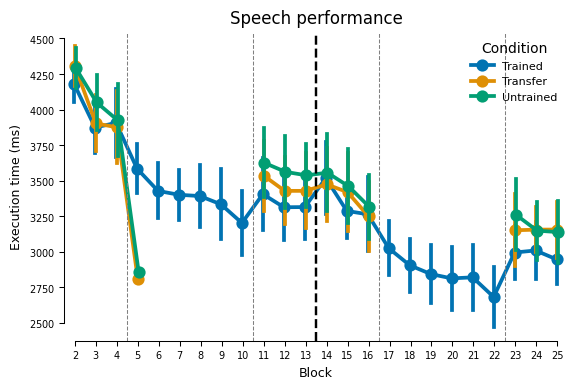

In [4]:
speech_blocks = utils.per_block(trials, "speech")
plotting.plot_blocks(speech_blocks, "ET", "speech", ylabel="Execution time (ms)");

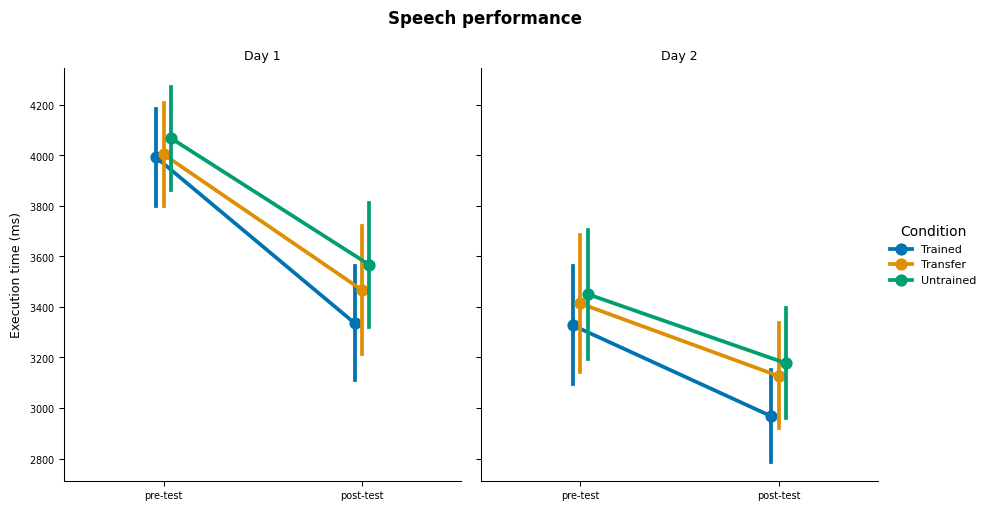

In [12]:
speech_prepost = utils.per_test_phase(trials, "speech")
plotting.plot_prepost(speech_prepost, "ET", "speech", ylabel="Execution time (ms)");

In [13]:
utils.learning_tests(speech_prepost)

,window,learning,n,mean_pre,mean_post,post_minus_pre,T,dof,p,cohen_d
0,day 1,specific,8,-75.938,-230.000,-154.062,-2.805,7,0.026,0.812
1,day 1,transfer,8,-64.062,-99.375,-35.312,-1.087,7,0.313,0.360
2,day 2,specific,8,-123.438,-209.375,-85.938,-1.371,7,0.213,0.450
3,day 2,transfer,8,-36.875,-50.312,-13.438,-0.385,7,0.712,0.136
4,day 1 pre -> day 2 post,specific,8,-75.938,-209.375,-133.438,-2.074,7,0.077,0.655
5,day 1 pre -> day 2 post,transfer,8,-64.062,-50.312,13.750,0.310,7,0.766,0.123


## Right hand

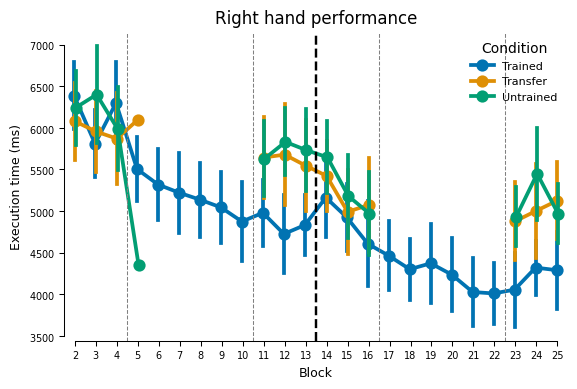

In [14]:
hand_blocks = utils.per_block(trials, "hand")
plotting.plot_blocks(hand_blocks, "ET", "hand", ylabel="Execution time (ms)");

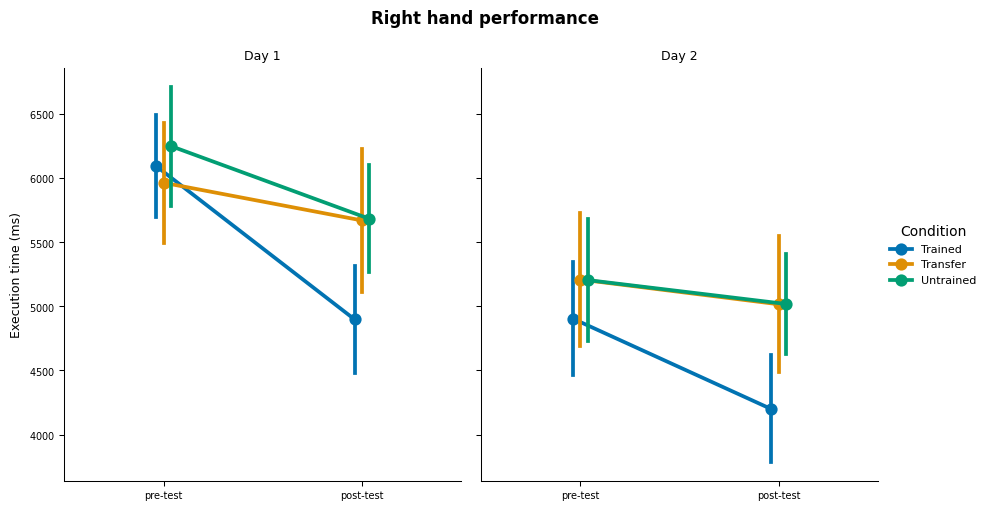

In [15]:
hand_prepost = utils.per_test_phase(trials, "hand")
plotting.plot_prepost(hand_prepost, "ET", "hand", ylabel="Execution time (ms)");

In [16]:
utils.learning_tests(hand_prepost)

,window,learning,n,mean_pre,mean_post,post_minus_pre,T,dof,p,cohen_d
0,day 1,specific,8,-155.625,-783.125,-627.500,-2.508,7,0.041,0.970
1,day 1,transfer,8,-285.312,-12.500,272.812,1.889,7,0.101,0.515
2,day 2,specific,8,-300.000,-818.125,-518.125,-3.167,7,0.016,0.814
3,day 2,transfer,8,4.375,-2.188,-6.562,-0.048,7,0.963,0.010
4,day 1 pre -> day 2 post,specific,8,-155.625,-818.125,-662.500,-3.002,7,0.020,1.068
5,day 1 pre -> day 2 post,transfer,8,-285.312,-2.188,283.125,1.682,7,0.136,0.511


### Error rate

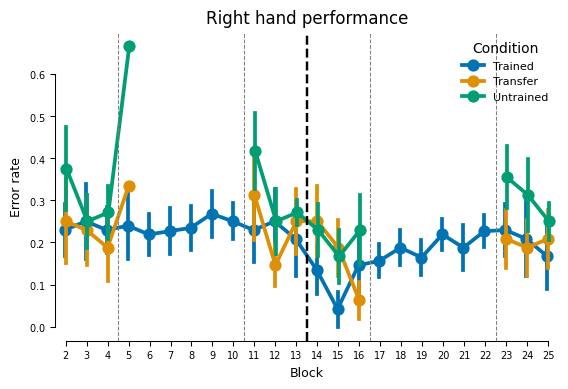

In [17]:
hand_errors = utils.error_rate_per_block(trials, "hand")
plotting.plot_blocks(hand_errors, "error_rate", "hand", ylabel="Error rate");

## Single subject

Block time course for one subject, to check individual data.

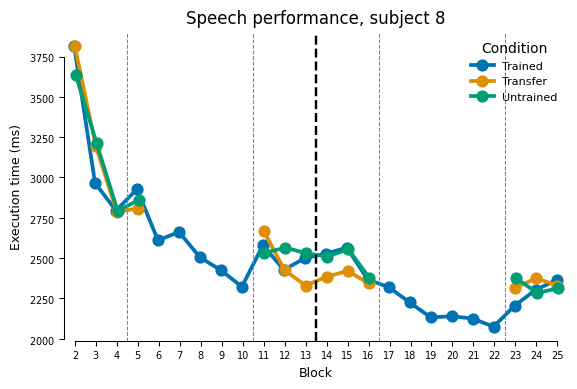

In [18]:
SUBJECT = 8

subject_blocks = utils.per_block(trials[trials["SubNum"] == SUBJECT], "speech")
ax = plotting.plot_blocks(subject_blocks, "ET", "speech", ylabel="Execution time (ms)")
ax.set_title(f"Speech performance, subject {SUBJECT}");